# Actividad integradora: Muestreo y Análisis Exploratorio de Datos (EDA)
**Capítulos 4 y 5** · Python (`pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib`)

El Colab sigue las 10 slides de la actividad. Los **100 patitos** son el ejemplo transversal; cada equipo repite los mismos pasos con su **dataset de Hugging Face**.

| Bloque | Slides | Secciones |
|---|---|---|
| Introducción | 1-2 | patitos, elección del dataset |
| Muestreo | 3-5 | 5 métodos, código, tabla de representatividad |
| EDA | 6-9 | exploración, descriptiva, 4 visualizaciones, comparación muestra vs población |
| Cierre | 10 | entregable y discusión |

**Antes de empezar:** elegí `DATASET` en la sección 2 y completá solo las celdas marcadas con `# >>> EDITAR`.

In [ ]:
import warnings, itertools; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")
SEED = 42
rng = np.random.default_rng(SEED)
# !pip -q install datasets      # necesario solo para descargar de Hugging Face

## Slide 1 · ¿Cómo estudiamos una población de patitos?
Tenemos **N = 100 patitos** (color, estanque, tamaño, peso). Queremos conocer sus características **sin estudiar a todos**: primero seleccionamos una muestra, después la exploramos.

**Objetivo:** seleccionar muestras, identificar patrones y evaluar **representatividad**.

In [ ]:
def make_ducks(N=100):
    colores = rng.choice(["amarillo", "blanco", "negro", "marrón", "naranja"], N, p=[.45, .25, .12, .12, .06])
    estanque = np.repeat(["Norte", "Sur", "Este", "Oeste"], N // 4)                 # ordenado por estanque (como un archivo real)
    efecto = {"amarillo": 0, "blanco": 40, "negro": 90, "marrón": 25, "naranja": -20}
    tam = rng.normal(20, 3, N) + pd.Series(estanque).map({"Norte": 0, "Sur": 1, "Este": 3, "Oeste": 5}).values
    peso = 60 + 4.5 * tam + pd.Series(colores).map(efecto).values + rng.normal(0, 12, N)
    return pd.DataFrame({"id": range(1, N + 1), "color": colores, "estanque": estanque,
                         "tamaño_cm": tam.round(1), "peso_g": peso.round(1)})

ducks = make_ducks()
print(ducks.shape); display(ducks.head())
print("Población: media peso =", round(ducks.peso_g.mean(), 2), "g | desvío =", round(ducks.peso_g.std(), 2))

(100, 5)


,id,color,estanque,tamaño_cm,peso_g
0,1,negro,Norte,21.2,245.3
1,2,amarillo,Norte,17.3,135.8
2,3,marrón,Norte,18.9,173.9
3,4,blanco,Norte,23.9,224.4
4,5,amarillo,Norte,18.9,146.3


Población: media peso = 184.84 g | desvío = 37.68


## Slide 2 · Elegí tu dataset de Hugging Face
| Temática | Dataset | Formato | Dificultad |
|---|---|---|---|
| Agro | Crop Yield | CSV | Baja |
| Medicina | PubMed RCT | Texto | Media |
| Facturas | SROIE | Imagen/OCR | Media |
| E-commerce | E-commerce | JSON | Baja |
| Visión artificial | COCO 2017 | Imagen/COCO | Alta |

**Consigna:** identificar *población*, *unidad de observación*, *tamaño*, variables *numéricas y categóricas*, y *limitaciones de representatividad*.

> **Los IDs de Hugging Face marcados como "verificar" hay que confirmarlos en el Hub** (buscá el nombre y copiá `usuario/dataset`). Mientras `USE_REAL = False` el Colab usa un generador sintético con la misma estructura, así corre sin internet.

In [ ]:
# >>> EDITAR: elegí tu dataset y, si querés datos reales, poné USE_REAL = True
DATASET  = "agro"          # "agro" | "pubmed" | "facturas" | "ecommerce" | "coco"
USE_REAL = False
MAX_ROWS = 20000           # Colab: trabajar con un subconjunto manejable (primeros MAX_ROWS registros en streaming)

CONFIG = {
 "agro": dict(nombre="Crop Yield", hf_id=None,                       # >>> verificar ID en el Hub
              unidad="una parcela/registro de cultivo", num="rendimiento", num2="lluvia_mm", cat="cultivo", cluster="region"),
 "pubmed": dict(nombre="PubMed RCT", hf_id="rmaanc/pubmed-rct20k",   # >>> verificar ID
              unidad="una oración de un resumen", num="n_palabras", num2="n_chars", cat="label", cluster="articulo",
              text_col="text"),
 "facturas": dict(nombre="SROIE", hf_id="darentang/sroie",           # >>> verificar ID
              unidad="un ticket/factura", num="total", num2="n_chars", cat="rubro", cluster="comercio", text_col="ocr_text"),
 "ecommerce": dict(nombre="E-commerce", hf_id=None,                  # >>> verificar ID
              unidad="un pedido", num="precio", num2="cantidad", cat="categoria", cluster="cliente"),
 "coco": dict(nombre="COCO 2017", hf_id="detection-datasets/coco",   # >>> verificar ID
              unidad="una imagen con sus anotaciones", num="n_anotaciones", num2="ancho", cat="supercategoria", cluster="fuente",
              image_col="image", list_col="objects"),
}
cfg = CONFIG[DATASET]; NUM, NUM2, CAT, CLU = cfg["num"], cfg["num2"], cfg["cat"], cfg["cluster"]
print(f"Dataset: {cfg['nombre']} | unidad de observación: {cfg['unidad']}")

Dataset: Crop Yield | unidad de observación: una parcela/registro de cultivo


In [ ]:
# ---------- Generadores sintéticos (misma estructura que el dataset real; ordenados por conglomerado, como un archivo real)
def _by_cluster(n_clusters, N):
    sizes = rng.multinomial(N, rng.dirichlet(np.ones(n_clusters) * 3))
    return np.repeat(np.arange(n_clusters), sizes)

def synth_agro(N=3000):
    c = _by_cluster(12, N); efecto = rng.normal(0, 1.2, 12)[c]
    lluvia = rng.normal(800, 150, N) + efecto * 60
    cultivo = rng.choice(["maíz", "soja", "trigo", "girasol", "cebada"], N, p=[.35, .3, .2, .1, .05])
    base = pd.Series(cultivo).map({"maíz": 9, "soja": 3.2, "trigo": 4, "girasol": 2.5, "cebada": 4.5}).values
    rend = base * (1 + (lluvia - 800) / 2500) + efecto * .4 + rng.normal(0, .6, N)
    return pd.DataFrame({"region": [f"R{i+1:02d}" for i in c], "cultivo": cultivo, "lluvia_mm": lluvia.round(1),
                         "temperatura": rng.normal(19, 3, N).round(1), "rendimiento": rend.round(2)})

def synth_pubmed(N=4000):
    art = np.repeat(np.arange(N // 8 + 1), 8)[:N]
    lab = np.tile(["BACKGROUND", "OBJECTIVE", "METHODS", "RESULTS", "CONCLUSIONS"], N // 5 + 1)[:N]
    lab = np.where(rng.random(N) < .15, rng.choice(["METHODS", "RESULTS"], N), lab)
    nw = np.maximum(3, rng.lognormal(2.9, .45, N) * pd.Series(lab).map({"METHODS": 1.2, "RESULTS": 1.3}).fillna(.9).values).astype(int)
    texts = [" ".join(rng.choice(["patient", "trial", "group", "dose", "effect", "placebo", "outcome", "week"], k)) for k in nw]
    return pd.DataFrame({"articulo": [f"A{a:04d}" for a in art], "label": lab, "text": texts})

def synth_facturas(N=800):
    c = _by_cluster(40, N); rubro = pd.Series(rng.choice(["supermercado", "restaurante", "farmacia", "ferretería"], 40))[c].values
    total = rng.lognormal(3.2, .8, N) * pd.Series(rubro).map({"supermercado": 2.5, "restaurante": 1.5, "farmacia": 1, "ferretería": 2}).values
    texts = ["x" * int(rng.normal(180, 40) + t / 3) for t in total]
    return pd.DataFrame({"comercio": [f"C{i:02d}" for i in c], "rubro": rubro, "total": total.round(2), "ocr_text": texts,
                         "img_w": rng.choice([400, 500, 600], N), "img_h": rng.integers(700, 1400, N)})

def synth_ecommerce(N=5000):
    c = _by_cluster(500, N)
    cat = rng.choice(["electrónica", "hogar", "moda", "deportes", "libros", "juguetes"], N, p=[.25, .2, .25, .1, .1, .1])
    precio = rng.lognormal(3.5, .9, N) * pd.Series(cat).map({"electrónica": 6, "hogar": 2.5, "moda": 1.5, "deportes": 2, "libros": .6, "juguetes": 1}).values
    return pd.DataFrame({"cliente": [f"U{i:04d}" for i in c], "categoria": cat, "precio": precio.round(2),
                         "cantidad": rng.poisson(1.5, N) + 1, "dispositivo": rng.choice(["móvil", "web", "app"], N, p=[.5, .3, .2])})

def synth_coco(N=2000):
    c = _by_cluster(8, N); sup = rng.choice(["persona", "vehículo", "animal", "comida", "interior", "deporte"], N, p=[.35, .2, .1, .1, .15, .1])
    return pd.DataFrame({"fuente": [f"flickr_{i}" for i in c], "supercategoria": sup,
                         "ancho": rng.choice([640, 480, 500, 427], N, p=[.5, .2, .2, .1]), "alto": rng.choice([480, 640, 375, 333], N),
                         "n_anotaciones": rng.poisson(pd.Series(sup).map({"persona": 9, "vehículo": 6, "animal": 3, "comida": 4, "interior": 7, "deporte": 6}).values) + 1})

SYNTH = {"agro": synth_agro, "pubmed": synth_pubmed, "facturas": synth_facturas, "ecommerce": synth_ecommerce, "coco": synth_coco}

In [ ]:
# ---------- Carga real (streaming de Hugging Face) + metadatos para texto e imágenes
def load_real(cfg, max_rows=MAX_ROWS, split="train"):
    from datasets import load_dataset
    ds = load_dataset(cfg["hf_id"], split=split, streaming=True)
    return pd.DataFrame(list(itertools.islice(ds, max_rows)))

def add_metadata(df, cfg):
    df = df.copy()
    if cfg.get("text_col") in df:                                         # texto: longitud
        df["n_chars"] = df[cfg["text_col"]].astype(str).str.len(); df["n_palabras"] = df[cfg["text_col"]].astype(str).str.split().str.len()
    if cfg.get("image_col") in df:                                        # imagen: dimensiones
        df["ancho"] = df[cfg["image_col"]].map(lambda im: im.size[0]); df["alto"] = df[cfg["image_col"]].map(lambda im: im.size[1])
    if cfg.get("list_col") in df:                                         # COCO: cantidad de anotaciones
        df["n_anotaciones"] = df[cfg["list_col"]].map(lambda o: len(o["bbox"]) if isinstance(o, dict) else len(o))
    if "n_chars" not in df and "ocr_text" in df: df["n_chars"] = df["ocr_text"].str.len()
    if "n_palabras" not in df and "text" in df:  df["n_palabras"] = df["text"].str.split().str.len()
    return df

def ensure_cluster(df, col, block=10):
    # Si el dataset real no trae conglomerado natural, usamos bloques de registros consecutivos (PROXY: documentarlo en el informe)
    if col not in df: df[col] = "B" + (np.arange(len(df)) // block).astype(str); print(f"⚠ '{col}' no existe: se usan bloques de {block} registros consecutivos como conglomerados")
    return df

if USE_REAL and cfg["hf_id"]:
    raw = load_real(cfg)
    print("Columnas reales:", list(raw.columns))     # >>> EDITAR el CONFIG si los nombres difieren
else:
    raw = SYNTH[DATASET]()
df = ensure_cluster(add_metadata(raw, cfg), CLU)
for c in df.columns:                                  # evita objetos no hashables/imágenes en las tablas
    if df[c].map(lambda v: isinstance(v, (dict, list))).any(): df = df.drop(columns=c)
df = df.drop(columns=[c for c in [cfg.get("image_col")] if c in df]) if cfg.get("image_col") else df
N = len(df); print(f"N = {N} registros | {df.shape[1]} columnas")

N = 3000 registros | 5 columnas


In [ ]:
# ---------- Ficha del dataset (consigna de la slide 2)
num_cols = df.select_dtypes("number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols and df[c].nunique() <= 60]
ficha = {"Población": f"todos los registros de {cfg['nombre']} (aquí: {N}; subconjunto de trabajo si MAX_ROWS < total)",
         "Unidad de observación": cfg["unidad"], "Tamaño N": N,
         "Variables numéricas": num_cols, "Variables categóricas": cat_cols,
         "Variable numérica de estudio": NUM, "Variable categórica (estratos)": CAT, "Conglomerados": CLU}
for k, v in ficha.items(): print(f"{k:34s}: {v}")
print("\nLimitaciones de representatividad (completar): ¿el subconjunto es el inicio del archivo? ¿hay orden por fecha/fuente? ¿faltan categorías raras?")

Población                         : todos los registros de Crop Yield (aquí: 3000; subconjunto de trabajo si MAX_ROWS < total)
Unidad de observación             : una parcela/registro de cultivo
Tamaño N                          : 3000
Variables numéricas               : ['lluvia_mm', 'temperatura', 'rendimiento']
Variables categóricas             : ['region', 'cultivo']
Variable numérica de estudio      : rendimiento
Variable categórica (estratos)    : cultivo
Conglomerados                     : region

Limitaciones de representatividad (completar): ¿el subconjunto es el inicio del archivo? ¿hay orden por fecha/fuente? ¿faltan categorías raras?


## Slide 3 · Cinco formas de seleccionar patitos
| Método | Ejemplo con patitos | Aplicación al dataset |
|---|---|---|
| Aleatorio simple | 10 patitos al azar | 10 % de los registros al azar |
| Estratificado | 10 % de cada color | muestrear dentro de cada categoría |
| Sistemático | cada décimo patito | un registro cada *k* |
| Conglomerados | estanques completos | grupos reales (región, artículo, comercio…) |
| Conveniencia | los 10 más cercanos | primeros registros del archivo |

In [ ]:
def m_simple(df, n, seed=SEED, **k):        return df.sample(n=n, random_state=seed)
def m_estratificado(df, n, cat, seed=SEED, **k):
    f = n / len(df)                                                       # misma fracción en cada estrato
    return pd.concat([g.sample(n=max(1, round(len(g) * f)), random_state=seed) for _, g in df.groupby(cat)])
def m_sistematico(df, n, seed=SEED, **k):
    paso = len(df) // n; ini = int(np.random.default_rng(seed).integers(paso))   # arranque aleatorio en [0, k)
    return df.iloc[ini::paso].head(n)
def m_conglomerados(df, n, clu, seed=SEED, **k):
    orden = np.random.default_rng(seed).permutation(df[clu].unique()); tam = df[clu].value_counts(); elegidos, tot = [], 0
    for c in orden:                                                       # grupos completos hasta alcanzar ~n (tamaño final varía)
        elegidos.append(c); tot += tam[c]
        if tot >= n: break
    return df[df[clu].isin(elegidos)]
def m_conveniencia(df, n, **k):             return df.head(n)

def tomar_muestras(df, n, cat, clu, seed=SEED):
    return {"Aleatorio simple": m_simple(df, n, seed), "Estratificado": m_estratificado(df, n, cat, seed),
            "Sistemático": m_sistematico(df, n, seed), "Conglomerados": m_conglomerados(df, n, clu, seed),
            "Conveniencia": m_conveniencia(df, n)}

# --- Demo con los patitos (n = 10)
patito_muestras = tomar_muestras(ducks, 10, "color", "estanque")
for k, s in patito_muestras.items(): print(f"{k:17s} n={len(s):3d} ids={s.id.tolist()}")

Aleatorio simple  n= 10 ids=[84, 54, 71, 46, 45, 40, 23, 81, 11, 1]
Estratificado     n= 12 ids=[91, 68, 69, 98, 84, 38, 58, 40, 12, 23, 55, 64]
Sistemático       n= 10 ids=[1, 11, 21, 31, 41, 51, 61, 71, 81, 91]
Conglomerados     n= 25 ids=[76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]
Conveniencia      n= 10 ids=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


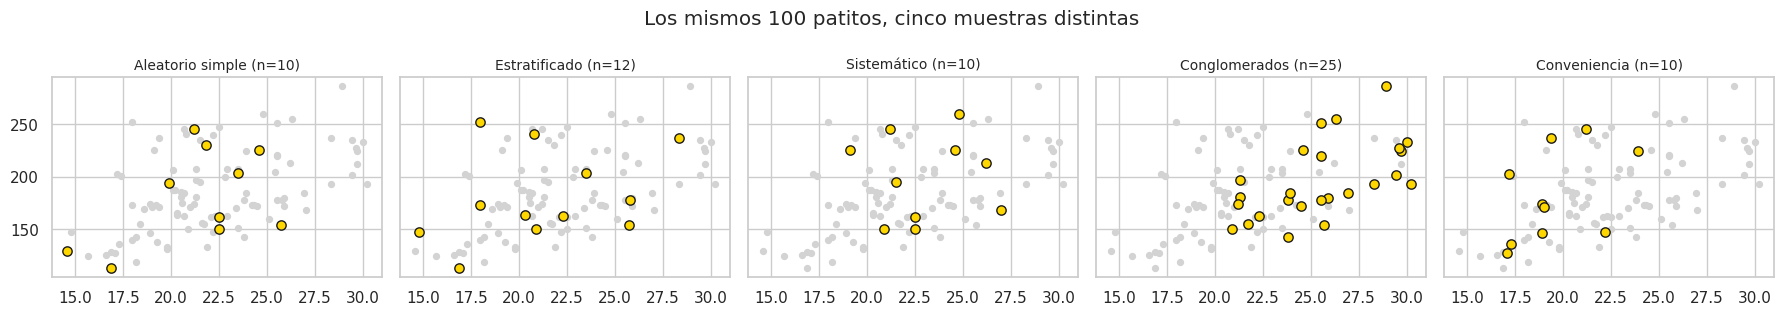

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2), sharey=True)
for ax, (k, s) in zip(axes, patito_muestras.items()):
    ax.scatter(ducks.tamaño_cm, ducks.peso_g, c="lightgray", s=18)
    ax.scatter(s.tamaño_cm, s.peso_g, c="gold", edgecolor="k", s=45); ax.set_title(f"{k} (n={len(s)})", fontsize=10)
plt.suptitle("Los mismos 100 patitos, cinco muestras distintas"); plt.tight_layout(); plt.show()

## Slide 4 · Aplicá el muestreo con Python
Funciones: `df.sample()`, `groupby().sample()`, selección sistemática con `iloc[inicio::k]` y selección de grupos completos con `isin()`.

**Consideraciones**
- **Datasets pequeños:** subir la proporción (p. ej. 20-30 %) para que cada estrato tenga registros.
- **Datasets grandes:** trabajar con un subconjunto manejable (`MAX_ROWS`).
- **PubMed:** los artículos funcionan como conglomerados (se muestrean artículos enteros, con todas sus oraciones).
- **COCO:** seleccionar imágenes completas con sus anotaciones (nunca anotaciones sueltas).
- **Registrar** diferencias en tamaños y **probabilidades de selección**.

In [ ]:
# >>> EDITAR: tamaño de muestra (~10 % por defecto; aumentar si el dataset es chico)
n = max(30, int(0.10 * N)) if N >= 300 else int(0.25 * N)
muestras = tomar_muestras(df, n, CAT, CLU)

# Probabilidades de inclusión teóricas por registro
k_sis = N // n; n_clu = df[CLU].nunique(); m_clu = df[CLU].nunique() and len(muestras["Conglomerados"][CLU].unique())
prob = pd.DataFrame({
  "Método": list(muestras),
  "n obtenido": [len(s) for s in muestras.values()],
  "Prob. de inclusión": [f"n/N = {n/N:.3f}", "≈ n/N en cada estrato", f"1/k = 1/{k_sis} = {1/k_sis:.3f}",
                         f"{m_clu}/{n_clu} clusters = {m_clu/n_clu:.3f} (todos los registros del cluster)", "no definida (0 fuera de los primeros n)"]})
display(prob)

,Método,n obtenido,Prob. de inclusión
0,Aleatorio simple,300,n/N = 0.100
1,Estratificado,299,≈ n/N en cada estrato
2,Sistemático,300,1/k = 1/10 = 0.100
3,Conglomerados,466,2/12 clusters = 0.167 (todos los registros del...
4,Conveniencia,300,no definida (0 fuera de los primeros n)


## Slide 5 · ¿Todas las muestras representan lo mismo?
$$f=\frac{n}{N}$$

**Pregunta:** ¿qué categorías desaparecieron o quedaron sobrerrepresentadas? (pp = puntos porcentuales respecto de la población)

In [ ]:
def tabla_representatividad(df, muestras, cat):
    pob = df[cat].value_counts(normalize=True); filas = []
    for nombre, s in muestras.items():
        prop = s[cat].value_counts(normalize=True).reindex(pob.index).fillna(0); d = prop - pob
        filas.append({"Método": nombre, "Tamaño": len(s), "Fracción f=n/N": round(len(s) / len(df), 4),
                      "Categorías presentes": f"{(prop > 0).sum()}/{len(pob)}",
                      "Desaparecidas": ", ".join(map(str, pob.index[prop == 0])) or "—",
                      "Más sobrerrep. (pp)": f"{d.idxmax()} ({d.max()*100:+.1f})", "Más subrep. (pp)": f"{d.idxmin()} ({d.min()*100:+.1f})"})
    return pd.DataFrame(filas).set_index("Método")

print("— Patitos (n=10) —");  display(tabla_representatividad(ducks, patito_muestras, "color"))
print(f"— {cfg['nombre']} (n≈{n}) —"); display(tabla_representatividad(df, muestras, CAT))

— Patitos (n=10) —


,Tamaño,Fracción f=n/N,Categorías presentes,Desaparecidas,Más sobrerrep. (pp),Más subrep. (pp)
Método,,,,,,
Aleatorio simple,10,0.10,5/5,—,naranja (+6.0),amarillo (-16.0)
Estratificado,12,0.12,5/5,—,naranja (+4.3),amarillo (-4.3)
Sistemático,10,0.10,3/5,"marrón, naranja",negro (+15.0),marrón (-8.0)
Conglomerados,25,0.25,4/5,marrón,amarillo (+10.0),marrón (-8.0)
Conveniencia,10,0.10,5/5,—,negro (+15.0),amarillo (-16.0)


— Crop Yield (n≈300) —


,Tamaño,Fracción f=n/N,Categorías presentes,Desaparecidas,Más sobrerrep. (pp),Más subrep. (pp)
Método,,,,,,
Aleatorio simple,300,0.1000,5/5,—,trigo (+1.9),maíz (-2.4)
Estratificado,299,0.0997,5/5,—,soja (+0.1),cebada (-0.1)
Sistemático,300,0.1000,5/5,—,girasol (+3.9),maíz (-2.4)
Conglomerados,466,0.1553,5/5,—,maíz (+1.0),trigo (-1.1)
Conveniencia,300,0.1000,5/5,—,trigo (+2.9),maíz (-4.1)


## Slide 6 · Exploración inicial: ¿qué datos tenemos?
Identificar tipos de variables, **faltantes, duplicados e inconsistencias**. Para texto e imágenes se construyen **metadatos** (longitud, dimensiones, cantidad de anotaciones, categorías) — ya generados en `add_metadata`.

In [ ]:
print(df.shape); display(df.head()); df.info()
display(df.describe(include="all").T)
print("Faltantes por columna:\n", df.isna().sum()); print("Duplicados:", df.duplicated().sum())

# Inconsistencias típicas: valores imposibles, categorías con distinto formato
for c in num_cols: print(f"{c:15s} min={df[c].min():>10.2f}  max={df[c].max():>10.2f}  negativos={(df[c] < 0).sum()}")
print({c: df[c].nunique() for c in cat_cols})

(3000, 5)


,region,cultivo,lluvia_mm,temperatura,rendimiento
0,R01,maíz,663.2,16.1,8.74
1,R01,soja,743.6,13.9,2.95
2,R01,maíz,836.1,18.5,7.08
3,R01,maíz,527.3,15.2,7.60
4,R01,maíz,667.4,15.0,9.31


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   region       3000 non-null   object 
 1   cultivo      3000 non-null   object 
 2   lluvia_mm    3000 non-null   float64
 3   temperatura  3000 non-null   float64
 4   rendimiento  3000 non-null   float64
dtypes: float64(3), object(2)
memory usage: 117.3+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
region,3000,12,R08,425,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cultivo,3000,5,maíz,1102,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lluvia_mm,3000.0,NaN,NaN,NaN,825.193833,157.601492,279.3,719.35,828.9,931.825,1314.1
temperatura,3000.0,NaN,NaN,NaN,18.900967,3.005377,9.6,16.9,18.85,20.9,31.5
rendimiento,3000.0,NaN,NaN,NaN,5.717587,2.871687,0.74,3.4,4.45,8.83,12.11


Faltantes por columna:
 region         0
cultivo        0
lluvia_mm      0
temperatura    0
rendimiento    0
dtype: int64
Duplicados: 0
lluvia_mm       min=    279.30  max=   1314.10  negativos=0
temperatura     min=      9.60  max=     31.50  negativos=0
rendimiento     min=      0.74  max=     12.11  negativos=0
{'region': 12, 'cultivo': 5}


## Slide 7 · Estadística descriptiva: ¿cómo son nuestros patitos?
$$\bar X=\frac{\sum X_i}{n}\qquad s^2=\frac{\sum (X_i-\bar X)^2}{n-1}\qquad IQR=Q_3-Q_1$$
Numéricas: media, mediana, varianza, desvío, mínimo, máximo, rango, cuartiles e IQR. Categóricas: frecuencias absolutas y relativas.

In [ ]:
def desc_num(d, cols):
    t = d[cols].agg(["mean", "median", "var", "std", "min", "max"]).T
    t["rango"] = t["max"] - t["min"]; t["Q1"] = d[cols].quantile(.25); t["Q3"] = d[cols].quantile(.75); t["IQR"] = t["Q3"] - t["Q1"]
    return t.round(3)
def desc_cat(d, col):
    vc = d[col].value_counts(); return pd.DataFrame({"f_abs": vc, "f_rel": (vc / len(d)).round(4)})

print("Patitos"); display(desc_num(ducks, ["peso_g", "tamaño_cm"])); display(desc_cat(ducks, "color"))
print(cfg["nombre"]);  display(desc_num(df, [NUM, NUM2])); display(desc_cat(df, CAT))

Patitos


,mean,median,var,std,min,max,rango,Q1,Q3,IQR
peso_g,184.838,178.10,1419.845,37.681,113.5,285.9,172.4,158.9,208.30,49.40
tamaño_cm,22.206,21.65,13.574,3.684,14.6,30.2,15.6,19.7,24.65,4.95


,f_abs,f_rel
color,,
amarillo,46,0.46
blanco,27,0.27
negro,15,0.15
marrón,8,0.08
naranja,4,0.04


Crop Yield


,mean,median,var,std,min,max,rango,Q1,Q3,IQR
rendimiento,5.718,4.45,8.247,2.872,0.74,12.11,11.37,3.40,8.830,5.430
lluvia_mm,825.194,828.90,24838.230,157.601,279.30,1314.10,1034.80,719.35,931.825,212.475


,f_abs,f_rel
cultivo,,
maíz,1102,0.3673
soja,889,0.2963
trigo,593,0.1977
girasol,283,0.0943
cebada,133,0.0443


## Slide 8 · Visualización: cuatro formas de entender los datos
| Gráfico | Qué muestra |
|---|---|
| Histograma | distribución de la variable numérica |
| Barras | frecuencia por categoría |
| Boxplot | mediana, cuartiles y valores atípicos (por categoría) |
| Dispersión | relación entre dos variables numéricas |

> Si un gráfico no corresponde a tu dataset (p. ej. no hay dos numéricas), **reemplazalo y justificá** la elección en el informe.

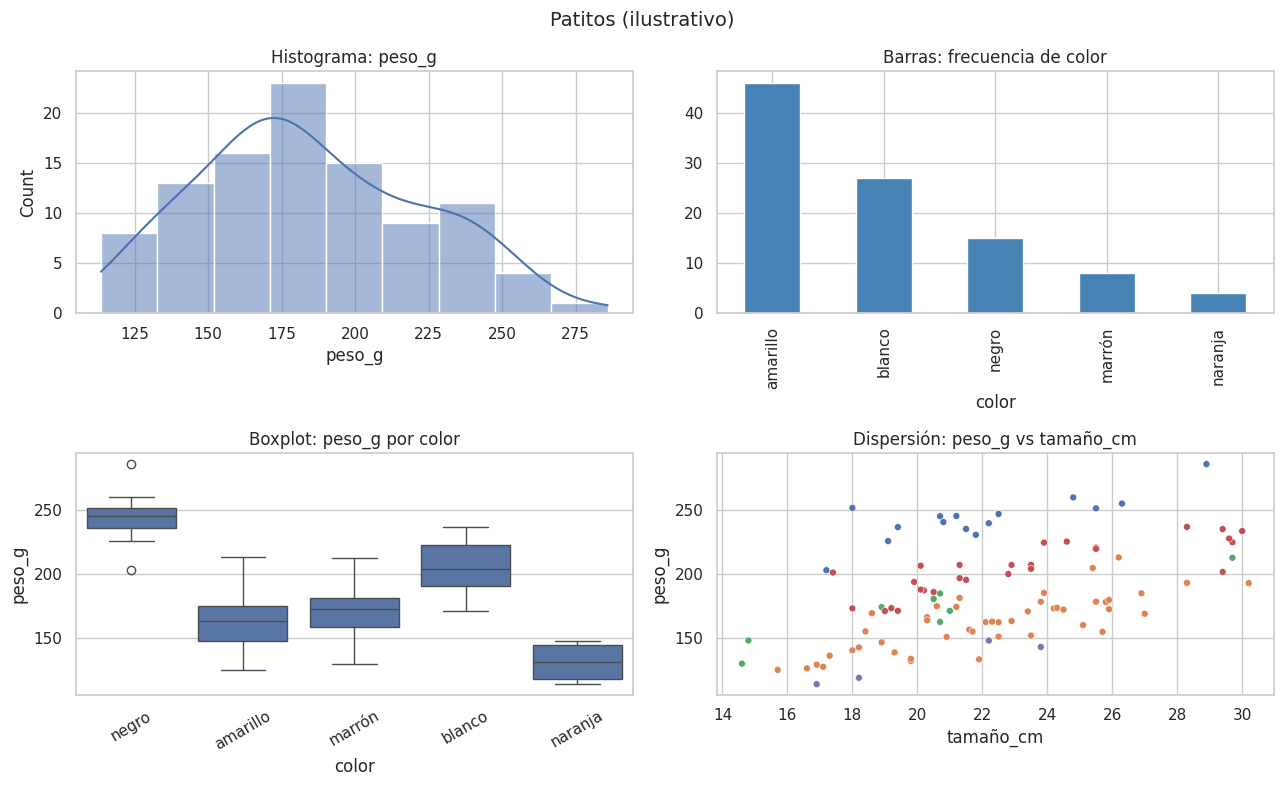

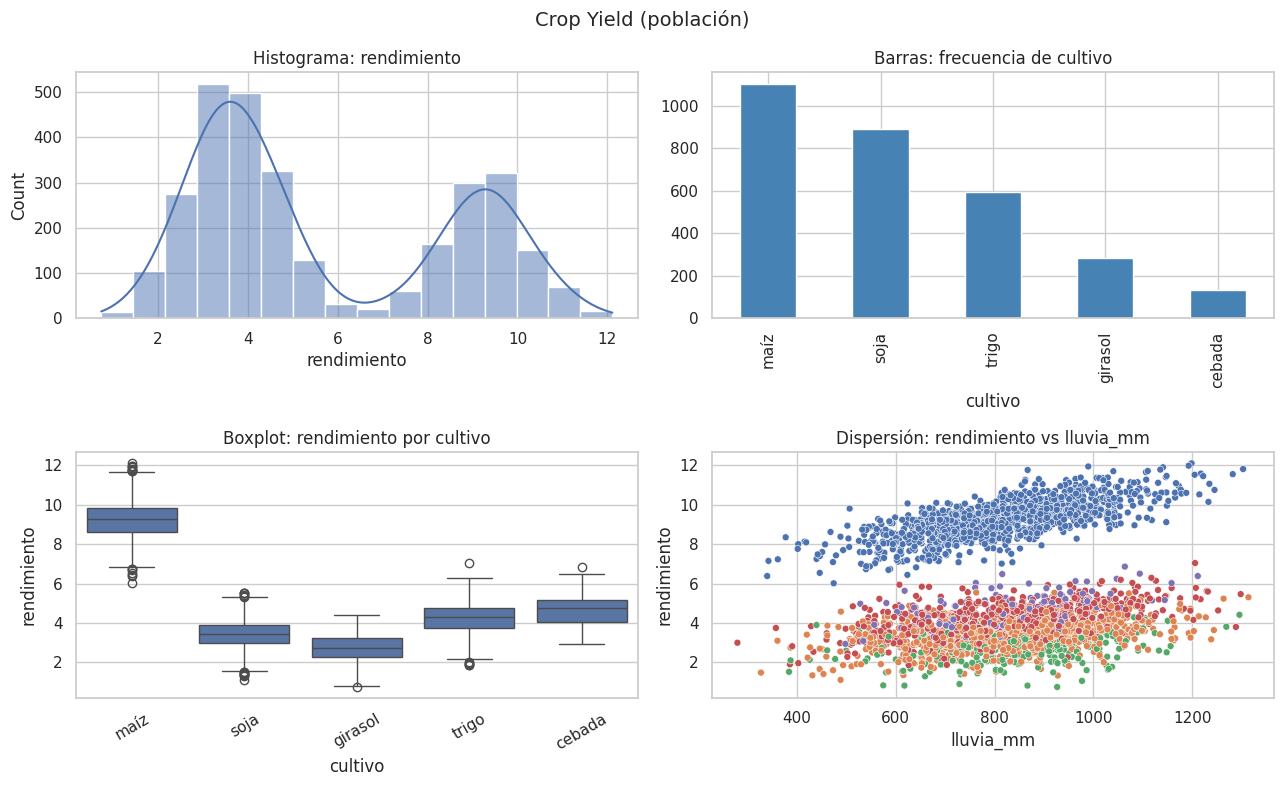

In [ ]:
def cuatro_graficos(d, num, num2, cat, titulo):
    fig, ax = plt.subplots(2, 2, figsize=(13, 8))
    sns.histplot(d[num], kde=True, ax=ax[0, 0]); ax[0, 0].set_title(f"Histograma: {num}")
    d[cat].value_counts().plot.bar(ax=ax[0, 1], color="steelblue"); ax[0, 1].set_title(f"Barras: frecuencia de {cat}")
    sns.boxplot(data=d, x=cat, y=num, ax=ax[1, 0]); ax[1, 0].set_title(f"Boxplot: {num} por {cat}"); ax[1, 0].tick_params(axis="x", rotation=30)
    sns.scatterplot(data=d, x=num2, y=num, hue=cat, ax=ax[1, 1], s=25, legend=False); ax[1, 1].set_title(f"Dispersión: {num} vs {num2}")
    fig.suptitle(titulo, fontsize=14); plt.tight_layout(); plt.show()

cuatro_graficos(ducks, "peso_g", "tamaño_cm", "color", "Patitos (ilustrativo)")
cuatro_graficos(df, NUM, NUM2, CAT, f"{cfg['nombre']} (población)")

## Slide 9 · Comparación: ¿qué muestra representa mejor la población?
$$e=\bar X_{\text{muestra}}-\mu_{\text{dataset}}\qquad e_{\text{relativo}}=\frac{|e|}{|\mu_{\text{dataset}}|}\times 100$$
El error relativo requiere una media de referencia **distinta de cero**.

Se comparan las cinco muestras con el dataset completo en: media y dispersión, proporciones de categorías, valores extremos, distribuciones y posibles sesgos de selección.

In [ ]:
def comparar(df, muestras, num, cat):
    mu, sd = df[num].mean(), df[num].std(); pob = df[cat].value_counts(normalize=True)
    q1, q3 = df[num].quantile([.25, .75]); lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)       # fences de la población
    filas = []
    for nombre, s in muestras.items():
        e = s[num].mean() - mu; e_rel = abs(e) / abs(mu) * 100 if mu != 0 else np.nan
        prop = s[cat].value_counts(normalize=True).reindex(pob.index).fillna(0)
        ks = stats.ks_2samp(s[num].dropna(), df[num].dropna())
        filas.append({"Método": nombre, "n": len(s), "media": s[num].mean(), "e": e, "e relativo %": e_rel,
                      "desvío": s[num].std(), "desvío/pob": s[num].std() / sd,
                      "mín": s[num].min(), "máx": s[num].max(), "atípicos (fence pob.)": int(((s[num] < lo) | (s[num] > hi)).sum()),
                      "TVD categorías": 0.5 * (prop - pob).abs().sum(), "KS D": ks.statistic, "KS p": ks.pvalue})
    return pd.DataFrame(filas).set_index("Método").round(4)

print("Patitos (peso_g)"); display(comparar(ducks, patito_muestras, "peso_g", "color"))
print(f"{cfg['nombre']} ({NUM})"); tabla9 = comparar(df, muestras, NUM, CAT); display(tabla9)

Patitos (peso_g)


,n,media,e,e relativo %,desvío,desvío/pob,mín,máx,atípicos (fence pob.),TVD categorías,KS D,KS p
Método,,,,,,,,,,,,
Aleatorio simple,10,180.8900,-3.9480,2.1359,45.2093,1.1998,113.5,245.3,0,0.1600,0.23,0.6604
Estratificado,12,181.3083,-3.5297,1.9096,42.8228,1.1365,113.5,251.6,0,0.0633,0.18,0.8214
Sistemático,10,199.5900,14.7520,7.9810,39.9977,1.0615,150.5,259.8,0,0.1900,0.26,0.5083
Conglomerados,25,196.1480,11.3100,6.1189,36.0610,0.9570,142.7,285.9,1,0.1100,0.22,0.2652
Conveniencia,10,181.0700,-3.7680,2.0385,43.4617,1.1534,127.1,245.3,0,0.2300,0.22,0.7113


Crop Yield (rendimiento)


,n,media,e,e relativo %,desvío,desvío/pob,mín,máx,atípicos (fence pob.),TVD categorías,KS D,KS p
Método,,,,,,,,,,,,
Aleatorio simple,300,5.5972,-0.1204,2.1050,2.8544,0.9940,1.34,11.82,0,0.0293,0.0480,0.5430
Estratificado,299,5.7656,0.0480,0.8395,2.9191,1.0165,1.66,11.95,0,0.0019,0.0280,0.9790
Sistemático,300,5.4465,-0.2711,4.7413,2.8371,0.9880,0.81,11.31,0,0.0460,0.0693,0.1398
Conglomerados,466,5.6020,-0.1156,2.0220,2.8946,1.0080,0.74,11.77,0,0.0176,0.0588,0.1180
Conveniencia,300,5.9606,0.2430,4.2509,2.9400,1.0238,0.74,12.11,0,0.0537,0.1280,0.0002


**Cómo leer la tabla**
- `e` y `e relativo %`: error **de esta muestra concreta**.
- `TVD categorías` (distancia de variación total, 0 a 1): 0 = proporciones idénticas a la población.
- `KS D / p`: test de Kolmogorov-Smirnov de dos muestras. Un `p` bajo indica que la distribución difiere. Con **conglomerados y conveniencia** los registros no son independientes, así que el p-valor es solo orientativo.
- ⚠ **El error observado de una muestra no equivale automáticamente al sesgo del método.** Para separar *suerte* de *sesgo* hay que repetir el muestreo muchas veces (a continuación).

,media de medias,sesgo (media - μ),desvío (variabilidad),RMSE
Aleatorio simple,5.7192,0.0016,0.1591,0.1589
Estratificado,5.7194,0.0018,0.0502,0.0502
Sistemático,5.7212,0.0036,0.1450,0.1448
Conglomerados,5.7060,-0.0116,0.3441,0.3437
Conveniencia,5.9606,0.2430,0.0000,0.2430


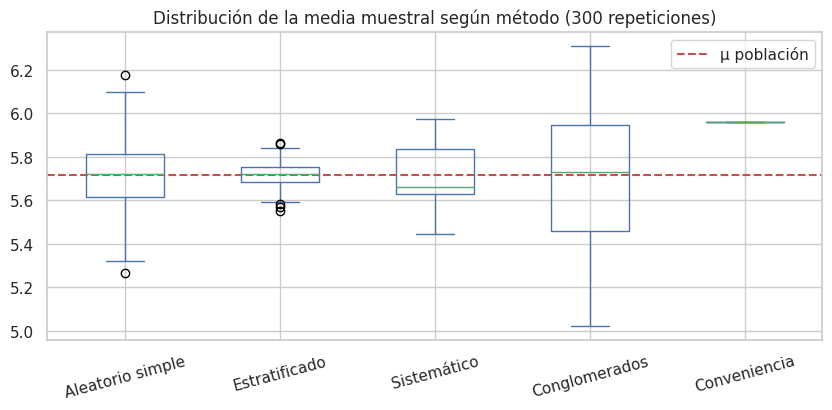

In [ ]:
# Sesgo vs error: repetimos cada método R veces con semillas distintas
def simular(df, n, num, cat, clu, R=300):
    mu = df[num].mean(); res = {k: [] for k in ["Aleatorio simple", "Estratificado", "Sistemático", "Conglomerados", "Conveniencia"]}
    for r in range(R):
        for k, s in tomar_muestras(df, n, cat, clu, seed=r).items(): res[k].append(s[num].mean())
    sim = pd.DataFrame(res)
    resumen = pd.DataFrame({"media de medias": sim.mean(), "sesgo (media - μ)": sim.mean() - mu, "desvío (variabilidad)": sim.std(),
                            "RMSE": np.sqrt(((sim - mu) ** 2).mean())}).round(4)
    return sim, resumen, mu

sim, resumen, mu = simular(df, n, NUM, CAT, CLU)
display(resumen)
sim.plot.box(figsize=(10, 4), rot=15); plt.axhline(mu, color="r", ls="--", label="μ población"); plt.legend()
plt.title("Distribución de la media muestral según método (300 repeticiones)"); plt.show()

In [ ]:
# Pregunta de la slide: "si seleccionamos solo patitos grandes, ¿estimamos bien el peso promedio?"
grandes = ducks.nlargest(10, "tamaño_cm"); print("Peso medio de los 10 más grandes:", grandes.peso_g.mean().round(1), "g vs población:", ducks.peso_g.mean().round(1), "g")

# Dos equipos, mismo estanque: ¿llegan a conclusiones distintas?  IC95% por bootstrap de cada muestra
for equipo, seed in {"Equipo A": 1, "Equipo B": 2}.items():
    s = m_simple(df, n, seed)[NUM]
    ic = stats.bootstrap((s.values,), np.mean, n_resamples=2000, random_state=SEED).confidence_interval
    print(f"{equipo} (semilla {seed}): media={s.mean():.3f}  IC95%=[{ic.low:.3f}, {ic.high:.3f}]  ¿contiene μ={mu:.3f}? {ic.low <= mu <= ic.high}")

Peso medio de los 10 más grandes: 224.3 g vs población: 184.8 g
Equipo A (semilla 1): media=5.621  IC95%=[5.312, 5.955]  ¿contiene μ=5.718? True
Equipo B (semilla 2): media=5.706  IC95%=[5.399, 6.009]  ¿contiene μ=5.718? True


## Slide 10 · Entregable y discusión final
**Notebook de Google Colab** con:
1. Dataset, población, pregunta de investigación y variables.
2. Cinco métodos de muestreo (o justificación de los no aplicables).
3. Tabla comparativa de muestras.
4. Exploración de estructura, faltantes y duplicados.
5. Estadística descriptiva.
6. Cuatro visualizaciones pertinentes.
7. Comparación de muestras con el dataset original.
8. Conclusiones sobre representatividad y limitaciones.

> **Pregunta final:** si dos equipos seleccionan muestras diferentes del mismo estanque, ¿pueden llegar a conclusiones distintas sobre los patitos? ¿Cómo determinar cuál representa mejor la población?